# Geospatial Visualization

When data has a location, a map can show patterns that no table reveals: clusters, corridors, gaps. Maps also mislead easily: large areas dominate the eye, and raw counts on a map often show only where people live. This lesson builds static and interactive maps with **GeoPandas** and **Folium**.

**After this lesson you can:**

1. Read vector geodata (shapefiles, GeoJSON) and explain coordinate reference systems (CRS).
2. Draw choropleth maps and normalise them correctly (counts vs rates vs density).
3. Choose a classification scheme for colour bins.
4. Build an interactive web map with Folium.

**Data:** NYC TLC taxi zone boundaries (263 zones) and yellow taxi trips, January 2024.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    """One month of NYC yellow taxi trips with the cleaning rules of M08 Lesson 08."""
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

import geopandas as gpd

gdf = gpd.read_file(f"zip://{datasets.fetch('taxi_zones.zip')}!taxi_zones/taxi_zones.shp")
print("GeoPandas", gpd.__version__, "| zones:", len(gdf), "| CRS:", gdf.crs.name, f"(EPSG:{gdf.crs.to_epsg()})")
gdf.head(3)

GeoPandas 1.2.0 | zones: 263 | CRS: NAD83 / New York Long Island (ftUS) (EPSG:2263)


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."


## 1. Geometries and Coordinate Reference Systems

A **GeoDataFrame** is a DataFrame with a `geometry` column (points, lines, polygons). Every geometry has coordinates in a **coordinate reference system (CRS)**:

| CRS | Units | Use |
| :--- | :--- | :--- |
| EPSG:4326 (WGS 84) | degrees of longitude/latitude | GPS, web maps, data exchange |
| EPSG:3857 (Web Mercator) | metres (distorted) | tiles of web maps; **never** for areas or distances |
| EPSG:2263 (NY State Plane, Long Island) | US feet | accurate local measurement in New York |

To measure areas or distances, use a **projected** CRS that is accurate for the region.

In [2]:
gdf["area_km2"] = gdf.geometry.area * 0.3048 ** 2 / 1e6          # EPSG:2263 is in US feet
web = gdf.to_crs(3857)
gdf["area_km2_webmercator"] = web.geometry.area / 1e6
print(gdf[["zone", "borough", "area_km2", "area_km2_webmercator"]].sort_values("area_km2", ascending=False).head(4).round(2))
ratio = (gdf["area_km2_webmercator"] / gdf["area_km2"]).mean()
print(f"\nWeb Mercator overstates areas in New York by a factor of {ratio:.2f} (latitude ~40.7°)")

                            zone        borough  area_km2  \
22       Bloomfield/Emerson Hill  Staten Island     19.65   
131                  JFK Airport         Queens     18.22   
117  Heartland Village/Todt Hill  Staten Island     17.18   
43        Charleston/Tottenville  Staten Island     13.55   

     area_km2_webmercator  
22                  34.13  
131                 31.68  
117                 29.81  
43                  23.47  

Web Mercator overstates areas in New York by a factor of 1.74 (latitude ~40.7°)


## 2. A Choropleth: Counts, Rates, Density

A **choropleth** colours each area by a value. Three versions of "where do taxi trips start?" give different stories:

1. **raw counts**: dominated by busy, often large, zones;
2. **density** (trips per km²): removes the effect of zone size;
3. **share** of something (for example the share of card payments): a rate that does not depend on volume.

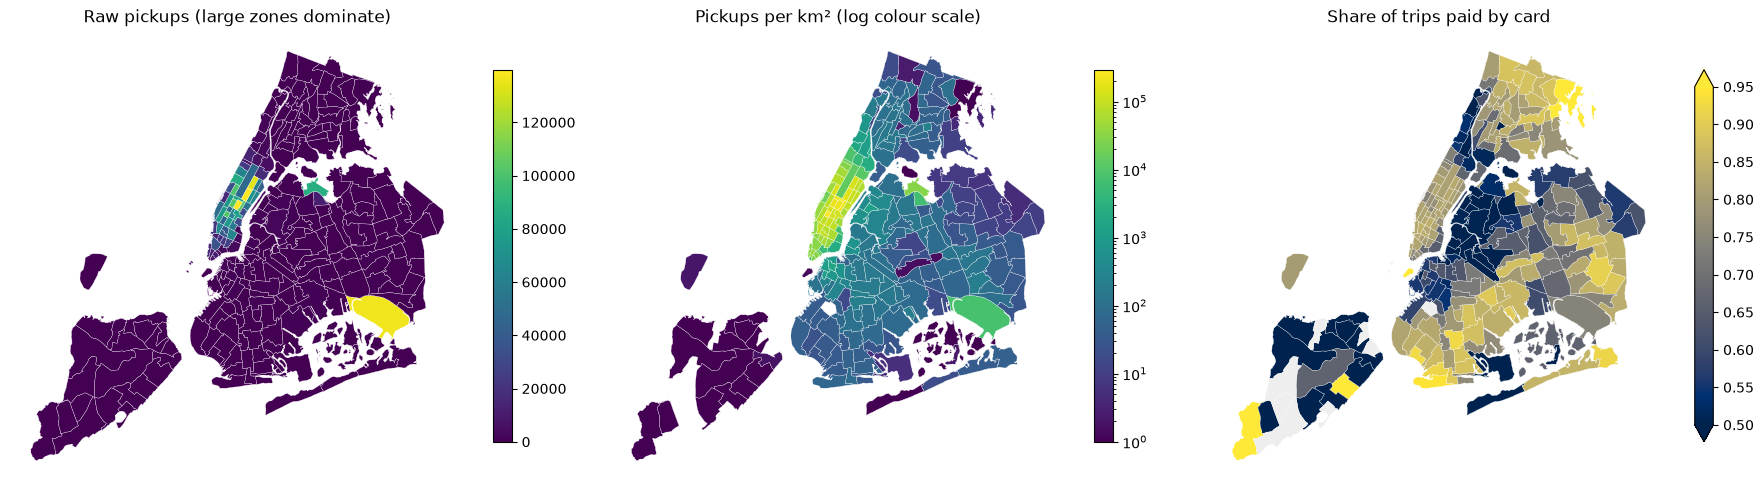

In [3]:
trips = load_month("2024-01")
per_zone = trips.groupby("PULocationID").agg(trips=("fare_amount", "size"), card_share=("payment_type", lambda s: (s == 1).mean()),
                                             median_tip=("tip_amount", "median"))
m = gdf.merge(per_zone, left_on="LocationID", right_index=True, how="left").fillna({"trips": 0})
m["density"] = m["trips"] / m["area_km2"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, col, title, kw in [
    (axes[0], "trips", "Raw pickups (large zones dominate)", {"cmap": "viridis"}),
    (axes[1], "density", "Pickups per km² (log colour scale)", {"cmap": "viridis", "norm": plt.matplotlib.colors.LogNorm(vmin=1, vmax=m["density"].max())}),
    (axes[2], "card_share", "Share of trips paid by card", {"cmap": "cividis", "vmin": 0.5, "vmax": 0.95}),
]:
    m.plot(column=col, ax=ax, legend=True, edgecolor="white", linewidth=0.2, missing_kwds={"color": "#EEEEEE"},
           legend_kwds={"shrink": 0.6}, **kw)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

The raw map highlights the two airports (large zones with many pickups); the density map shows that Manhattan is by far the most intense area; the card-share map shows where cash is still common. Choose the normalisation that matches the question.

## 3. Classification Schemes

A continuous colour scale can be dominated by a few extreme values. **Classed** maps put values into bins:

| Scheme | Bins | Good for |
| :--- | :--- | :--- |
| equal interval | same width | evenly spread data |
| quantiles | same number of areas | skewed data; ranks |
| natural breaks (Jenks) | groups of similar values | clustered data |

The density values are very skewed, so the choice changes the map a lot.

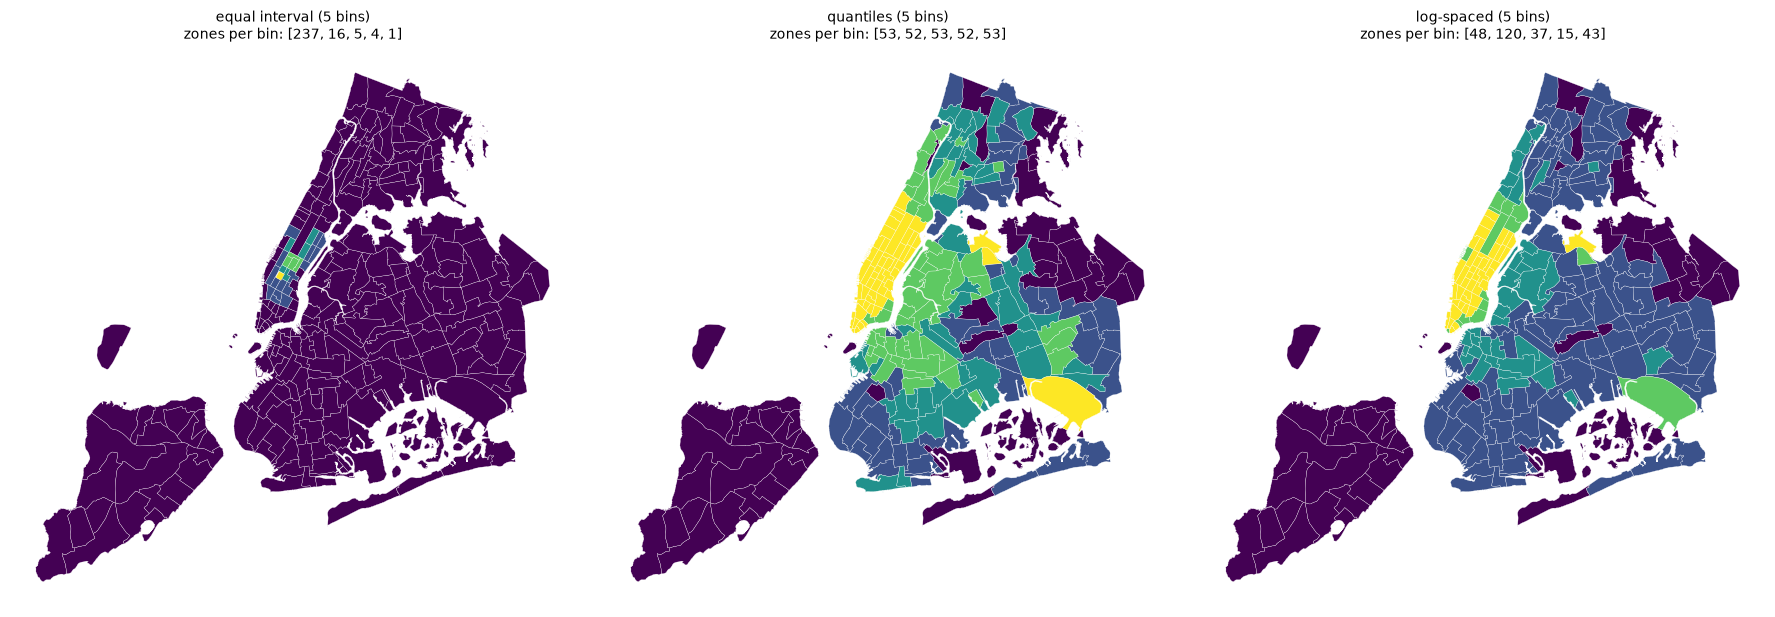

In [4]:
dens = m["density"]
schemes = {
    "equal interval (5 bins)": pd.cut(dens, 5, labels=False),
    "quantiles (5 bins)": pd.qcut(dens.rank(method="first"), 5, labels=False),
    "log-spaced (5 bins)": pd.cut(np.log10(dens.clip(lower=1)), 5, labels=False),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, bins) in zip(axes, schemes.items()):
    m.assign(bin=bins).plot(column="bin", categorical=True, cmap="viridis", ax=ax, edgecolor="white", linewidth=0.2)
    counts = bins.value_counts().sort_index().tolist()
    ax.set_title(f"{name}\nzones per bin: {counts}", fontsize=10)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

With equal intervals, almost all zones fall into the lowest bin; quantiles show the ranking but hide the size of the differences; log-spaced bins are a good compromise for data that spans several orders of magnitude.

## 4. Flows on a Map

Lines between zone centroids show **where trips go**. Only the strongest flows are drawn, otherwise the map becomes a hairball.

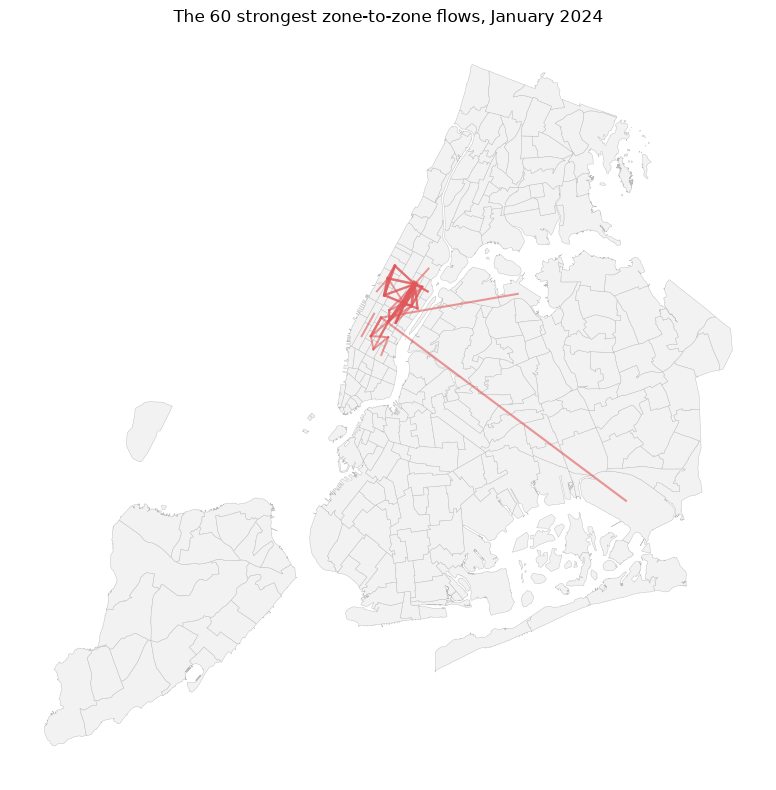

                  src                   dst     n
Upper East Side South Upper East Side North 21614
Upper East Side North Upper East Side South 19170
       Midtown Center Upper East Side South 10134
  Lincoln Square East Upper West Side South  8812
Upper East Side South        Midtown Center  8710


In [5]:
cent = gdf.set_index("LocationID").geometry.centroid
flows = (trips.groupby(["PULocationID", "DOLocationID"]).size().rename("n").reset_index()
         .query("PULocationID != DOLocationID and PULocationID in @cent.index and DOLocationID in @cent.index")
         .nlargest(60, "n"))
fig, ax = plt.subplots(figsize=(8, 8))
gdf.plot(ax=ax, color="#F2F2F2", edgecolor="#BBBBBB", linewidth=0.3)
for r in flows.itertuples():
    a, b = cent[r.PULocationID], cent[r.DOLocationID]
    ax.plot([a.x, b.x], [a.y, b.y], color="#E15759", alpha=0.6, lw=0.5 + 4 * r.n / flows["n"].max())
ax.set(title="The 60 strongest zone-to-zone flows, January 2024")
ax.set_axis_off()
plt.tight_layout()
plt.show()
names = zones.set_index("LocationID")["Zone"]
print(flows.head(5).assign(src=lambda d: d["PULocationID"].map(names), dst=lambda d: d["DOLocationID"].map(names))[["src", "dst", "n"]].to_string(index=False))

## 5. An Interactive Web Map with Folium

**Folium** creates Leaflet web maps from Python: tiles, zoom, pop-ups and tooltips. Web maps need WGS 84 coordinates (EPSG:4326). Simplifying the polygons keeps the HTML small.

In [6]:
import folium

web_gdf = m[["LocationID", "zone", "borough", "trips", "density", "geometry"]].copy()
web_gdf["geometry"] = web_gdf.geometry.simplify(100)            # 100 ft tolerance: much smaller file, same look
web_gdf = web_gdf.to_crs(4326)
web_gdf["log_density"] = np.log10(web_gdf["density"].clip(lower=1))

fmap = folium.Map(location=[40.73, -73.93], zoom_start=10, tiles="OpenStreetMap")
folium.Choropleth(geo_data=web_gdf.to_json(), data=web_gdf, columns=["LocationID", "log_density"],
                  key_on="feature.properties.LocationID", fill_color="YlGnBu", fill_opacity=0.7, line_weight=0.3,
                  legend_name="log10(pickups per km²)").add_to(fmap)
folium.GeoJson(web_gdf.to_json(), style_function=lambda f: {"fillOpacity": 0, "weight": 0},
               tooltip=folium.GeoJsonTooltip(fields=["zone", "borough", "trips"], aliases=["Zone", "Borough", "Pickups"])).add_to(fmap)
html_kb = len(fmap.get_root().render()) / 1024
print(f"map HTML: {html_kb:.0f} KiB")
fmap

map HTML: 841 KiB


Hover over a zone to see its name and pickups. In a notebook viewer that does not run JavaScript (for example GitHub), the interactive map does not appear; save it with `fmap.save("map.html")` and open it in a browser.

*Insight: On a map, area grabs attention. Normalise values (density, rate, share) unless you really want to show totals, pick colour bins that fit the distribution, and measure areas and distances in a projected CRS, never in degrees or Web Mercator.*

## Real-World Use Case or Analogy

A choropleth of raw counts is like **judging restaurants by the number of chairs**: the largest ones win, whatever the quality. Normalising (per km², per resident, share of trips) is like judging by occupancy rate.

Ride-hailing companies plan supply with zone maps, retailers choose store locations with population density maps, and epidemiologists map rates, not counts, so that large cities do not dominate every map.